In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import re              #Regular Expressions
import warnings

In [2]:
data_folder = "Netflix data set"
# Load movies dataset
movies = pd.read_csv("Netflix data set/movies.csv")

print("Movies Dataset Loaded Successfully!")
print(movies.head())
print("Movies Shape:", movies.shape)

Movies Dataset Loaded Successfully!
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
Movies Shape: (27278, 3)


In [3]:
# Load combined dataset.txt dataset

ratings_file = os.path.join(data_folder, "combined_data_1.txt")

with open(ratings_file, "r") as file:
    for i in range(10):
        print(file.readline().strip())

1:
1488844,3,2005-09-06
822109,5,2005-05-13
885013,4,2005-10-19
30878,4,2005-12-26
823519,3,2004-05-03
893988,3,2005-11-17
124105,4,2004-08-05
1248029,3,2004-04-22
1842128,4,2004-05-09


In [4]:
# raing loading

In [5]:
ratings = []
movie_id = None

with open(ratings_file, "r") as file:
    for line in file:
        line = line.strip()

        if line.endswith(":"):
            movie_id = int(line[:-1])
        else:
            user_id, rating, date = line.split(",")
            ratings.append([int(user_id), movie_id, int(rating), date])

        if len(ratings) >= 100000:
            break

ratings_df = pd.DataFrame(
    ratings,
    columns=["User_ID", "Movie_ID", "Rating", "Date"]
)

print("Ratings Dataset Loaded Successfully!")
print(ratings_df.head())
print("Ratings Shape:", ratings_df.shape)

Ratings Dataset Loaded Successfully!
   User_ID  Movie_ID  Rating        Date
0  1488844         1       3  2005-09-06
1   822109         1       5  2005-05-13
2   885013         1       4  2005-10-19
3    30878         1       4  2005-12-26
4   823519         1       3  2004-05-03
Ratings Shape: (100000, 4)


In [6]:
# Data cleaning

In [7]:
# Check missing values
print("Missing Values:")
print(ratings_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", ratings_df.duplicated().sum())

# Remove duplicate records
ratings_df = ratings_df.drop_duplicates()

# Check rating values
print("\nRating Distribution:")
print(ratings_df["Rating"].value_counts().sort_index())

# Convert Date column to datetime format
ratings_df["Date"] = pd.to_datetime(ratings_df["Date"])

# Final dataset information
print("\nFinal Dataset Shape:", ratings_df.shape)
print("\nDataset Information:")
ratings_df.info()

Missing Values:
User_ID     0
Movie_ID    0
Rating      0
Date        0
dtype: int64

Duplicate Records: 0

Rating Distribution:
Rating
1     5920
2    10949
3    28619
4    33021
5    21491
Name: count, dtype: int64

Final Dataset Shape: (100000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   User_ID   100000 non-null  int64         
 1   Movie_ID  100000 non-null  int64         
 2   Rating    100000 non-null  int64         
 3   Date      100000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(3)
memory usage: 3.1 MB


In [8]:
# Top 10 Most Rated Movies

In [9]:
top_movies = (
    ratings_df.groupby("Movie_ID")
    .agg(
        Total_Ratings=("Rating", "count"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Total_Ratings", ascending=False)
    .head(10)
    .round(2)
)

display(top_movies)

,Total_Ratings,Average_Rating
Movie_ID,,
28,39752,3.82
8,14910,3.19
18,10722,3.78
30,7202,3.76
17,7108,2.90
26,5861,2.79
16,2699,3.10
3,2012,3.64
24,1333,2.99


In [10]:
# Visualize Top 10 Movies

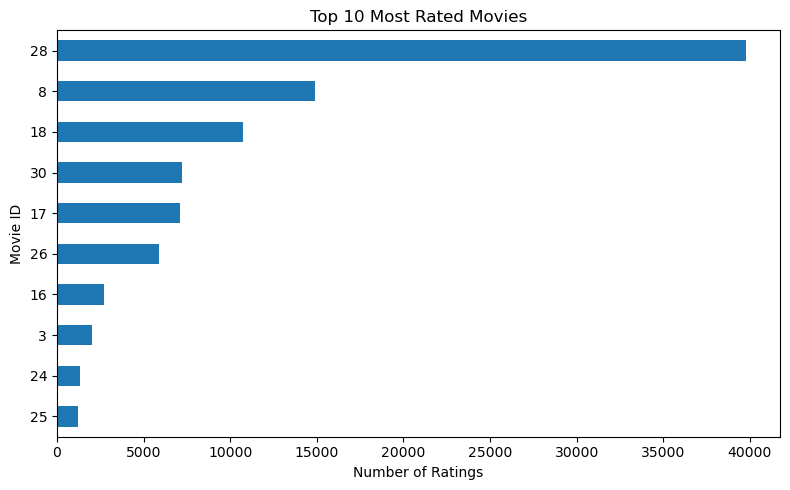

In [11]:
top_movies["Total_Ratings"].sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="Top 10 Most Rated Movies"
)

plt.xlabel("Number of Ratings")
plt.ylabel("Movie ID")
plt.tight_layout()
plt.show()

In [12]:
#Highest-Rated Movies

In [13]:
best_movies = (
    ratings_df.groupby("Movie_ID")
    .agg(
        Average_Rating=("Rating", "mean"),
        Total_Ratings=("Rating", "count")
    )
    .query("Total_Ratings >= 100")
    .sort_values("Average_Rating", ascending=False)
    .head(10)
)

display(best_movies.round(2))

,Average_Rating,Total_Ratings
Movie_ID,,
13,4.55,125
25,3.97,1207
5,3.92,1140
28,3.82,39752
18,3.78,10722
30,3.76,7202
1,3.75,547
3,3.64,2012
29,3.60,523


In [14]:
# Most Active Users

In [15]:
top_users = (
    ratings_df.groupby("User_ID")
    .agg(
        Total_Ratings=("Rating", "count"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Total_Ratings", ascending=False)
    .head(10)
    .round(2)
)

display(top_users)

,Total_Ratings,Average_Rating
User_ID,,
387418,28,1.61
305344,28,1.54
2439493,27,1.00
1664010,25,4.24
2118461,25,4.08
1932594,16,2.38
1461435,16,1.06
2056022,14,2.43
1314869,14,2.79


In [16]:
# Rating Distribution Graph

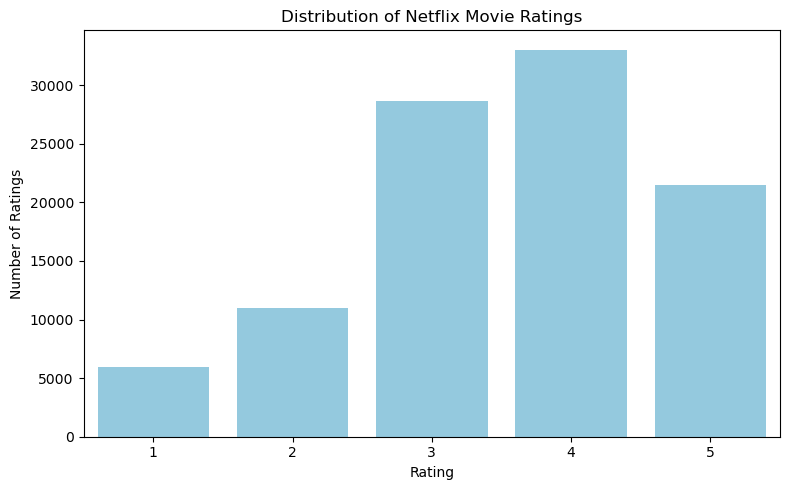

In [17]:
plt.figure(figsize=(8, 5))
sns.countplot(data=ratings_df, x="Rating", color="skyblue")

plt.title("Distribution of Netflix Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

Top-rated movies analysis

In [18]:
#Find the highest-rated movies

In [19]:
# Average rating and number of ratings for each movie
movie_stats = ratings_df.groupby("Movie_ID").agg(
    Average_Rating=("Rating", "mean"),
    Total_Ratings=("Rating", "count")
).reset_index()

# Show movies with at least 100 ratings
top_movies = movie_stats[movie_stats["Total_Ratings"] >= 100]

top_movies = top_movies.sort_values(
    by="Average_Rating", ascending=False
).head(10)

display(top_movies.round(2))

,Movie_ID,Average_Rating,Total_Ratings
12,13,4.55,125
24,25,3.97,1207
4,5,3.92,1140
27,28,3.82,39752
17,18,3.78,10722
29,30,3.76,7202
0,1,3.75,547
2,3,3.64,2012
28,29,3.60,523
1,2,3.56,145


In [20]:
# Check the columns in your ratings dataset
ratings_df.head()

,User_ID,Movie_ID,Rating,Date
0,1488844,1,3,2005-09-06
1,822109,1,5,2005-05-13
2,885013,1,4,2005-10-19
3,30878,1,4,2005-12-26
4,823519,1,3,2004-05-03


In [21]:
# Rating insights

In [22]:
print("Total ratings:", len(ratings_df))
print("Unique users:", ratings_df["User_ID"].nunique())
print("Unique movies:", ratings_df["Movie_ID"].nunique())
print("\nRating summary:")
print(ratings_df["Rating"].describe())
print("\nMissing values:")
print(ratings_df.isnull().sum())

Total ratings: 100000
Unique users: 81490
Unique movies: 30

Rating summary:
count    100000.000000
mean          3.532140
std           1.119366
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: Rating, dtype: float64

Missing values:
User_ID     0
Movie_ID    0
Rating      0
Date        0
dtype: int64


In [23]:
# Top 10 most-rated movies

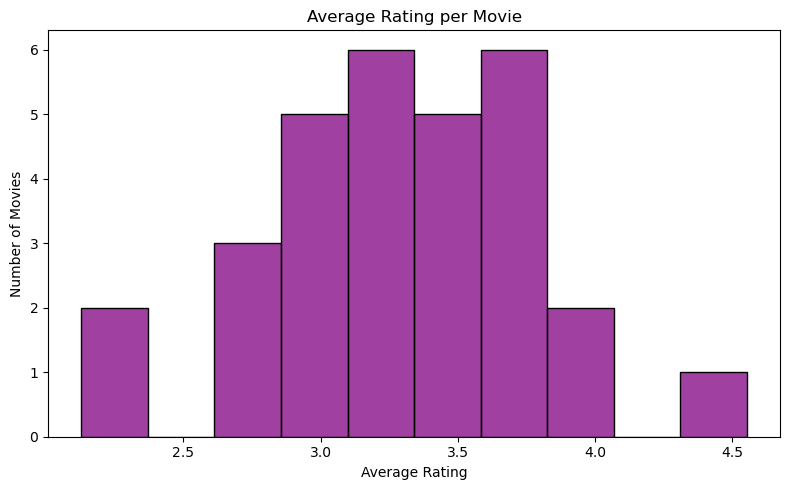

In [33]:
movie_ratings = ratings_df.groupby("Movie_ID")["Rating"].mean()

plt.figure(figsize=(8, 5))
sns.histplot(movie_ratings, bins=10, color="purple")
plt.title("Average Rating per Movie")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

In [25]:
# Recommendation model

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import LabelEncoder
import numpy as np

model_df = ratings_df[["User_ID", "Movie_ID", "Rating"]].dropna().copy()

# Limit data size to keep training manageable
if len(model_df) > 200000:
    model_df = model_df.sample(200000, random_state=42)

user_encoder = LabelEncoder()
movie_encoder = LabelEncoder()

model_df["user_idx"] = user_encoder.fit_transform(model_df["User_ID"])
model_df["movie_idx"] = movie_encoder.fit_transform(model_df["Movie_ID"])

train_df, test_df = train_test_split(
    model_df, test_size=0.2, random_state=42
)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 80000
Testing rows: 20000


In [27]:
# Train the recommendation model

In [34]:
global_mean = train_df["Rating"].mean()

train_matrix = train_df.pivot_table(
    index="user_idx",
    columns="movie_idx",
    values="Rating",
    aggfunc="mean"
)

centered_matrix = train_matrix.sub(global_mean).fillna(0)

svd = TruncatedSVD(n_components=20, random_state=42)

user_factors = svd.fit_transform(centered_matrix)
movie_factors = svd.components_

predicted_matrix = (user_factors @ movie_factors) + global_mean

print("Recommendation model trained successfully!")

Recommendation model trained successfully!


In [29]:
#Evaluate the model

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions = []
actuals = []

user_positions = {
    user: i for i, user in enumerate(train_matrix.index)
}
movie_positions = {
    movie: i for i, movie in enumerate(train_matrix.columns)
}

for _, row in test_df.iterrows():
    user_pos = user_positions.get(row["user_idx"])
    movie_pos = movie_positions.get(row["movie_idx"])

    if user_pos is not None and movie_pos is not None:
        predicted_rating = predicted_matrix[user_pos, movie_pos]
    else:
        predicted_rating = global_mean

    predicted_rating = np.clip(predicted_rating, 1, 5)

    predictions.append(predicted_rating)
    actuals.append(row["Rating"])

mae = mean_absolute_error(actuals, predictions)
rmse = np.sqrt(mean_squared_error(actuals, predictions))

print("Model Evaluation Results")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

Model Evaluation Results
MAE: 0.931
RMSE: 1.111


In [31]:
# Recommend movies to a user

In [36]:
user_id = ratings_df["User_ID"].iloc[0]
user_idx = user_encoder.transform([user_id])[0]

if user_idx in train_matrix.index:
    row_idx = train_matrix.index.get_loc(user_idx)
    scores = predicted_matrix[row_idx]

    movie_idx_list = train_matrix.columns.to_numpy()

    recommendations = pd.DataFrame({
        "movie_idx": movie_idx_list,
        "Movie_ID": movie_encoder.inverse_transform(movie_idx_list),
        "Predicted_Rating": scores
    })

    watched_movies = ratings_df.loc[
        ratings_df["User_ID"] == user_id, "Movie_ID"
    ].unique()

    recommendations = recommendations[
        ~recommendations["Movie_ID"].isin(watched_movies)
    ]

    recommendations = recommendations.sort_values(
        "Predicted_Rating", ascending=False
    )

    print("Recommended movies for User:", user_id)
    display(recommendations.head(10))
else:
    print("User not found in the training data.")

Recommended movies for User: 1488844


,movie_idx,Movie_ID,Predicted_Rating
14,14,15,3.548320
26,26,27,3.546592
18,18,19,3.538192
21,21,22,3.538036
11,11,12,3.537171
28,28,29,3.536433
24,24,25,3.535340
23,23,24,3.535318
2,2,3,3.535057
4,4,5,3.535026
